# 🤖 Desafio NPS — Fase 1 · Parte 4: Modelo Preditivo de Detratores

Na EDA (notebook anterior) fizemos o **Entendimento dos Dados** do ciclo **CRISP-DM** e descobrimos *por que* o NPS da empresa é tão baixo: o atraso na entrega e as reclamações acompanham as notas ruins. Agora avançamos para as fases de **Preparação dos Dados**, **Modelagem** e **Avaliação**, terminando com uma proposta de **Implantação (Deploy)**.

A pergunta muda de *"o que explica a nota?"* para *"conseguimos **antecipar** quem vai virar detrator, **antes** de a pesquisa chegar, para agir a tempo?"*

### 🎯 Meta de negócio × meta analítica

| | Definição |
|---|---|
| **Dor de negócio** | 84% dos clientes são detratores (NPS ≈ −80). A empresa só descobre a insatisfação depois que ela aconteceu. |
| **Meta de negócio** | Reduzir a proporção de detratores agindo **antes** da pesquisa, com o orçamento e a capacidade do SAC/CRM que existem hoje. |
| **Meta analítica** | Um modelo de **classificação** que entregue, para cada pedido, um **score de risco de detração**. Critério técnico: superar a regra simples de negócio (*"atrasou, é risco"*) em **AUC-ROC** e gerar **lift** na fatia de pedidos que o time consegue atender. |
| **Como será usado** | Lista diária de pedidos priorizados por risco para ação proativa (aviso de atraso, contato do SAC, compensação). |

### 🗺️ Roteiro
1. Configurações e importação dos dados
2. Definição da variável-alvo
3. Seleção das variáveis de entrada (e o cuidado com vazamento de dados)
4. Separação dos dados em treino e teste
5. Preparação dos dados com `Pipeline` e `ColumnTransformer`
6. Linha de base: o que conseguimos sem modelo?
7. Modelos candidatos e validação cruzada
8. Avaliação no conjunto de teste
9. Interpretação do modelo: o que pesa no risco?
10. Ponto de corte (threshold), custo do erro e lift
11. Complemento: prevendo a nota com regressão
12. Uso na prática: salvando o modelo e pontuando novos pedidos
13. Conclusões, limitações e próximos passos

> **Como usar no Colab:** execute as células em ordem (*Ambiente de execução → Executar tudo*). Se o arquivo `desafio_nps_fase_1.csv` ainda não estiver na sessão, a Célula 2 abre a janela de upload.

# 1. ⚙️ Configurações e importação dos dados

In [1]:
# ============================================================
# Célula 1 — Importando as bibliotecas e definindo as configurações
# ============================================================
import os
import warnings
warnings.filterwarnings("ignore")   # esconde avisos de versão para deixar a saída mais limpa

import numpy as np                  # cálculos numéricos
import pandas as pd                 # manipulação de tabelas (DataFrames)
import matplotlib.pyplot as plt     # gráficos
import seaborn as sns               # gráficos estatísticos
import joblib                       # salvar e carregar o modelo treinado (deploy)

# Separação dos dados e validação cruzada
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate

# Preparação dos dados: tratamento de nulos, padronização e variáveis dummies
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Modelos de classificação (e um modelo "bobo" para servir de linha de base)
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree
from sklearn.ensemble import RandomForestClassifier

# Métricas de classificação e de regressão
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix, classification_report,
                             mean_absolute_error, mean_squared_error, r2_score)

# Semente fixa: os mesmos resultados a cada execução (sorteio do treino/teste, árvores etc.)
SEED = 42
np.random.seed(SEED)

# Ajuste visual para os gráficos
sns.set(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

# Mostra mais colunas e números com 3 casas decimais nas tabelas
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", "{:.3f}".format)

# Cores fixas (as mesmas do notebook de EDA)
cores_nps = {"Detrator": "#E8622C", "Neutro": "#A8A69E", "Promotor": "#2A78D6"}

import sklearn
print("Bibliotecas carregadas! pandas", pd.__version__, "| scikit-learn", sklearn.__version__)

Bibliotecas carregadas! pandas 2.2.3 | scikit-learn 1.9.1


In [2]:
# ============================================================
# Célula 2 — Importando os dados
# ============================================================
# Procura o arquivo na pasta atual (Colab) ou na pasta data/ do repositório
candidatos = ["desafio_nps_fase_1.csv", "../data/desafio_nps_fase_1.csv", "data/desafio_nps_fase_1.csv"]
arquivo = next((c for c in candidatos if os.path.exists(c)), None)

# No Colab, se o arquivo ainda não estiver na sessão, abrimos a janela de upload
if arquivo is None:
    from google.colab import files
    enviado = files.upload()
    arquivo = list(enviado.keys())[0]

df = pd.read_csv(arquivo)

print("Formato da base (linhas, colunas):", df.shape)
print("Valores nulos na base inteira:", df.isnull().sum().sum())
df.head()

Formato da base (linhas, colunas): (2500, 19)
Valores nulos na base inteira: 0


,customer_id,customer_age,customer_region,customer_tenure_months,order_id,order_value,items_quantity,discount_value,payment_installments,delivery_time_days,delivery_delay_days,freight_value,delivery_attempts,customer_service_contacts,resolution_time_days,nps_score,repeat_purchase_30d,complaints_count,csat_internal_score
0,1,63,Nordeste,14,50001,139.730,4,39.350,4,2,2,55.530,3,0,4,6.900,0,3,6.500
1,2,20,Sul,1,50002,458.950,2,9.510,10,6,4,28.230,3,0,10,2.400,0,3,0.000
2,3,46,Nordeste,111,50003,507.060,5,42.820,6,6,1,40.990,1,4,5,4.800,0,7,1.500
3,4,52,Centro-Oeste,117,50004,302.190,2,19.580,9,5,2,35.240,3,1,11,5.900,0,4,0.300
4,5,56,Norte,50,50005,253.060,1,29.370,11,13,1,39.320,1,1,0,6.100,0,3,7.900


### 📝 Análise dos resultados


- A base é a mesma da EDA: **2.500 pedidos e 19 colunas**, sem nenhum valor nulo.
- Mesmo sem nulos hoje, vamos manter um passo de **imputação** dentro do pipeline: em produção, um pedido novo pode chegar com campo vazio, e o modelo não pode quebrar por isso.

# 2. 🎯 Definição da variável-alvo

O modelo precisa de uma pergunta com resposta **sim/não**. Seguindo a metodologia oficial do NPS (a mesma da EDA):

| Nota | Categoria | Variável-alvo `detrator` |
|---|---|---|
| 0 a 6 | Detrator | **1** (evento que queremos antecipar) |
| 7 e 8 | Neutro | 0 |
| 9 e 10 | Promotor | 0 |

Por que **detrator** e não a nota em si? Porque a **ação de negócio é binária**: a empresa vai *agir ou não agir* sobre um pedido. Prever a nota exata (regressão) é um complemento que faremos na Seção 11.

                  quantidade  proporcao_%
0 = não detrator         391       15.640
1 = detrator            2109       84.360


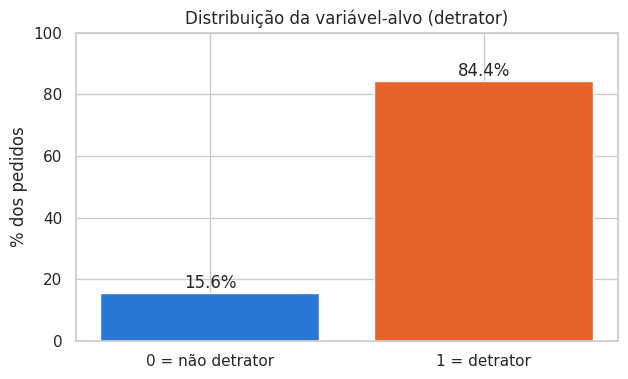

In [3]:
# ============================================================
# Célula 3 — Criando a variável-alvo (detrator = nota de 0 a 6)
# ============================================================
# pd.cut com right=False cria os intervalos [0, 7), [7, 9) e [9, 10]
df["categoria_nps"] = pd.cut(df["nps_score"], bins=[0, 7, 9, 10.01], right=False,
                             labels=["Detrator", "Neutro", "Promotor"])

# Target binária: 1 = detrator (classe positiva, o evento de interesse), 0 = não detrator
df["detrator"] = (df["categoria_nps"] == "Detrator").astype(int)

# Distribuição da target: quantidade e proporção de cada classe
distribuicao_alvo = pd.DataFrame({
    "quantidade": df["detrator"].value_counts().sort_index(),
    "proporcao_%": df["detrator"].value_counts(normalize=True).sort_index() * 100
})
distribuicao_alvo.index = ["0 = não detrator", "1 = detrator"]
print(distribuicao_alvo)

# Gráfico de barras com a proporção de cada classe
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(distribuicao_alvo.index, distribuicao_alvo["proporcao_%"],
       color=[cores_nps["Promotor"], cores_nps["Detrator"]])
for i, v in enumerate(distribuicao_alvo["proporcao_%"]):
    ax.text(i, v + 1.5, f"{v:.1f}%", ha="center", fontsize=12)
ax.set_title("Distribuição da variável-alvo (detrator)")
ax.set_ylabel("% dos pedidos")
ax.set_ylim(0, 100)
plt.show()

### 📝 Análise dos resultados


- **2.109 detratores (84,4%)** contra **391 não detratores (15,6%)**. A classe positiva escolhida (detrator) é a **maioria**, o oposto do desbalanceamento clássico (fraude, churn), em que o evento de interesse é raro.
- **Consequência para a avaliação:** um modelo que diga "todo mundo é detrator" acerta **84%** das vezes sem aprender nada. A **acurácia** é enganosa aqui, e até o recall e o F1 da classe detrator ficam altos "de graça". Por isso a comparação entre modelos será feita principalmente pela **AUC-ROC** (capacidade de ordenar os pedidos por risco) e pela **precisão acima da taxa base de 84%**.
- **Leitura de negócio:** a proporção mostra que a insatisfação é a regra, não a exceção. O modelo não vai "encontrar agulhas no palheiro"; o papel dele é **ordenar** os pedidos para que a ação comece pelos casos mais graves e **identificar a minoria que não precisa de ação**.

# 3. 🧩 Seleção das variáveis de entrada

A pergunta-chave para cada coluna é: **"essa informação existe no momento em que o modelo vai ser usado?"** Se uma variável só é conhecida *depois* da pesquisa (ou é outra forma de medir a própria nota), usá-la no treino gera **vazamento de dados (data leakage)**: o modelo fica ótimo no papel e inútil na prática.

Vamos primeiro confirmar com os dados as duas suspeitas de vazamento levantadas na EDA.

In [4]:
# ============================================================
# Célula 4 — Checando vazamento: recompra em 30 dias × nota de NPS
# ============================================================
# Na EDA, a recompra pareceu ser uma função direta da nota. Vamos conferir:
# quantos clientes recompraram em cada faixa de nota?
faixa_nota = pd.cut(df["nps_score"], bins=[0, 7, 8, 9, 10.01], right=False,
                    labels=["0 a 6,9", "7 a 7,9", "8 a 8,9", "9 a 10"])
recompra_por_faixa = df.groupby(faixa_nota, observed=True)["repeat_purchase_30d"].agg(["count", "mean"])
recompra_por_faixa.columns = ["pedidos", "taxa_recompra"]
print(recompra_por_faixa)

# E o CSAT interno: o quanto ele "anda junto" com a nota de NPS?
correlacao_csat = df[["csat_internal_score", "nps_score"]].corr(method="spearman").iloc[0, 1]
print(f"\nCorrelação de Spearman entre CSAT interno e NPS: {correlacao_csat:.3f}")

           pedidos  taxa_recompra
nps_score                        
0 a 6,9       2109          0.000
7 a 7,9        173          0.000
8 a 8,9        108          1.000
9 a 10         110          1.000



Correlação de Spearman entre CSAT interno e NPS: 0.561


### 📝 Análise dos resultados


- **Recompra em 30 dias:** é **0% em todas as notas abaixo de 8** e **100% em todas as notas a partir de 8**. Não existe cliente com nota 2 que recomprou nem cliente com nota 9 que não recomprou. Essa variável não é um comportamento independente: ela foi **calculada a partir da própria nota**. Usá-la como entrada seria um caso clássico de **vazamento de dados**: o modelo "acertaria" quase tudo no teste e não funcionaria no mundo real, porque a recompra só acontece **depois** da pesquisa.
- **CSAT interno:** correlação de Spearman de **0,561** com o NPS, uma relação moderada. Ele fica de fora por um motivo **conceitual**, não estatístico: é outra pesquisa de satisfação, coletada no mesmo momento da experiência. Usá-lo seria prever uma resposta de satisfação com outra resposta de satisfação, o que não ajuda a agir **antes**.

In [5]:
# ============================================================
# Célula 5 — Dicionário de seleção: o que entra e o que fica de fora
# ============================================================
# Para cada coluna registramos QUANDO ela é conhecida e a DECISÃO tomada.
selecao = pd.DataFrame([
    ["customer_id / order_id",   "identificador",          "Fora", "Só identifica a linha; não carrega informação de comportamento"],
    ["customer_age",             "antes da entrega",        "Entra", "Perfil do cliente (cadastro)"],
    ["customer_region",          "antes da entrega",        "Entra", "Perfil / logística (vira dummies)"],
    ["customer_tenure_months",   "antes da entrega",        "Entra", "Tempo de relacionamento (cadastro)"],
    ["order_value",              "no pedido",               "Entra", "Valor da compra"],
    ["items_quantity",           "no pedido",               "Entra", "Itens do pedido"],
    ["discount_value",           "no pedido",               "Entra", "Desconto concedido"],
    ["payment_installments",     "no pedido",               "Entra", "Parcelamento"],
    ["freight_value",            "no pedido",               "Entra", "Valor do frete"],
    ["delivery_time_days",       "na entrega",              "Entra", "Prazo total de entrega"],
    ["delivery_delay_days",      "na entrega",              "Entra", "Atraso em relação ao prometido"],
    ["delivery_attempts",        "na entrega",              "Entra", "Tentativas de entrega"],
    ["customer_service_contacts","pós-venda (a confirmar)", "Cenário B", "Contatos com o SAC"],
    ["complaints_count",         "pós-venda (a confirmar)", "Cenário B", "Reclamações registradas"],
    ["resolution_time_days",     "pós-venda (a confirmar)", "Cenário B", "Tempo de resolução"],
    ["csat_internal_score",      "junto/depois da pesquisa","Fora", "Outra medida de satisfação: seria usar a resposta para prever a resposta"],
    ["repeat_purchase_30d",      "depois da pesquisa",      "Fora", "Acontece depois e é calculada a partir da nota (vazamento)"],
    ["nps_score / categoria_nps","é a resposta",            "Fora", "Origem da variável-alvo"],
], columns=["variavel", "quando_e_conhecida", "decisao", "justificativa"])
selecao

,variavel,quando_e_conhecida,decisao,justificativa
0,customer_id / order_id,identificador,Fora,Só identifica a linha; não carrega informação ...
1,customer_age,antes da entrega,Entra,Perfil do cliente (cadastro)
2,customer_region,antes da entrega,Entra,Perfil / logística (vira dummies)
3,customer_tenure_months,antes da entrega,Entra,Tempo de relacionamento (cadastro)
4,order_value,no pedido,Entra,Valor da compra
5,items_quantity,no pedido,Entra,Itens do pedido
6,discount_value,no pedido,Entra,Desconto concedido
7,payment_installments,no pedido,Entra,Parcelamento
8,freight_value,no pedido,Entra,Valor do frete
9,delivery_time_days,na entrega,Entra,Prazo total de entrega


### 📝 Análise dos resultados


- **12 colunas entram** (perfil, pedido e entrega), **3 entram só no cenário B** (atendimento) e **6 ficam de fora** (IDs, CSAT, recompra e a própria nota).
- O ponto mais delicado são as variáveis de **atendimento**: a base não traz datas, então não sabemos se a reclamação foi registrada **antes** ou **depois** de o cliente responder à pesquisa. Em vez de esconder essa dúvida, vamos **medir o impacto dela** treinando dois cenários:
  - **Cenário A · momento da entrega:** só o que é certamente conhecido quando o pedido chega.
  - **Cenário B · após o pós-venda:** acrescenta contatos com o SAC, reclamações e tempo de resolução, **premissa que precisa ser confirmada** com a área de atendimento antes do deploy.

In [6]:
# ============================================================
# Célula 6 — Definindo as listas de variáveis para os dois cenários
# ============================================================
# Cenário A — "no momento da entrega": só o que já se sabe quando o pedido chega ao cliente
variaveis_cenario_a = ["customer_age", "customer_tenure_months", "order_value", "items_quantity",
                       "discount_value", "payment_installments", "freight_value",
                       "delivery_time_days", "delivery_delay_days", "delivery_attempts"]

# Cenário B — "após o pós-venda": soma as informações do atendimento (SAC)
variaveis_atendimento = ["customer_service_contacts", "complaints_count", "resolution_time_days"]
variaveis_cenario_b = variaveis_cenario_a + variaveis_atendimento

# Variável categórica (igual nos dois cenários)
variaveis_categoricas = ["customer_region"]

cenarios = {
    "A · momento da entrega": variaveis_cenario_a,
    "B · após o pós-venda":   variaveis_cenario_b,
}
for nome, lista in cenarios.items():
    print(f"{nome}: {len(lista)} numéricas + {len(variaveis_categoricas)} categórica")

A · momento da entrega: 10 numéricas + 1 categórica
B · após o pós-venda: 13 numéricas + 1 categórica


### 📝 Análise dos resultados


- O cenário A usa **10 variáveis numéricas**, o cenário B usa **13**; os dois incluem a região.
- Comparar os dois cenários responde a uma pergunta de negócio importante: **quanto vale a informação do atendimento** para antecipar o detrator? Se o ganho for pequeno, o modelo pode rodar mais cedo (logo na entrega); se for grande, vale esperar o pós-venda ou acelerar o registro das reclamações.

# 4. ✂️ Separação dos dados em treino e teste

O modelo aprende com o **treino** e é avaliado no **teste**, um conjunto que ele nunca viu, simulando os pedidos futuros. Usamos 80% / 20% com `random_state=42`, como nas aulas, e acrescentamos `stratify=y`: com uma classe muito maior que a outra, a estratificação garante a **mesma proporção de detratores** nos dois conjuntos.

> **Regra de ouro:** o conjunto de teste fica "guardado na gaveta" até a Seção 8. Todas as escolhas (modelo, parâmetros) são feitas com validação cruzada **dentro do treino**.

In [7]:
# ============================================================
# Célula 7 — Separando X (entradas) e y (target) e dividindo em treino/teste
# ============================================================
# X recebe TODAS as variáveis candidatas do cenário B; o cenário A usa um subconjunto delas
X = df[variaveis_cenario_b + variaveis_categoricas]
y = df["detrator"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y
)

# Conferindo tamanhos e a proporção de detratores em cada parte
resumo_divisao = pd.DataFrame({
    "linhas": [len(X_train), len(X_test)],
    "detratores": [y_train.sum(), y_test.sum()],
    "proporcao_detratores_%": [y_train.mean() * 100, y_test.mean() * 100],
}, index=["treino", "teste"])
resumo_divisao

,linhas,detratores,proporcao_detratores_%
treino,2000,1687,84.350
teste,500,422,84.400


### 📝 Análise dos resultados


- **Treino:** 2.000 pedidos (1.687 detratores, 84,35%). **Teste:** 500 pedidos (422 detratores, 84,40%).
- A estratificação funcionou: a proporção de detratores é praticamente a mesma nas duas partes, então o teste representa bem a base.
- **Limitação:** sem datas na base, não é possível fazer a separação mais realista, a **temporal** (treinar com os meses antigos e testar nos mais recentes). A divisão aleatória tende a ser um pouco otimista, porque o futuro pode ser diferente do passado.

# 5. 🧼 Preparação dos dados com `Pipeline` e `ColumnTransformer`

Montamos a preparação dentro de um **pipeline**, como nas aulas. Isso garante que tudo o que é "aprendido" com os dados (a mediana para preencher nulos, a média e o desvio-padrão da padronização, as categorias das dummies) seja calculado **somente com o treino** e depois apenas *aplicado* ao teste e aos pedidos novos. É mais uma proteção contra vazamento de dados.

| Tipo de coluna | Passo 1 | Passo 2 | Por quê |
|---|---|---|---|
| Numérica | `SimpleImputer(strategy="median")` | `StandardScaler()` | A base atual não tem nulos, mas os pedidos novos podem ter; a padronização deixa os coeficientes da regressão logística comparáveis |
| Categórica | `SimpleImputer(strategy="most_frequent")` | `OneHotEncoder(handle_unknown="ignore")` | Transforma a região em dummies; uma região nova não quebra o modelo |

In [8]:
# ============================================================
# Célula 8 — Função que monta o pré-processamento para uma lista de variáveis
# ============================================================
def criar_preprocessador(variaveis_numericas):
    """Recebe a lista de colunas numéricas e devolve o ColumnTransformer do cenário."""
    transformador_numerico = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),   # preenche nulos com a mediana do treino
        ("scaler", StandardScaler()),                    # média 0 e desvio-padrão 1
    ])
    transformador_categorico = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),  # preenche nulos com a categoria mais comum
        ("onehot", OneHotEncoder(handle_unknown="ignore")),    # cria uma coluna 0/1 por região
    ])
    return ColumnTransformer([
        ("num", transformador_numerico, variaveis_numericas),
        ("cat", transformador_categorico, variaveis_categoricas),
    ])

# Exemplo: como fica a matriz de entrada do cenário B depois da preparação
preprocessador_exemplo = criar_preprocessador(variaveis_cenario_b)
X_train_preparado = preprocessador_exemplo.fit_transform(X_train)   # fit SÓ no treino
print("Formato depois da preparação:", X_train_preparado.shape)
print("Colunas geradas:", list(preprocessador_exemplo.get_feature_names_out()))

Formato depois da preparação: (2000, 18)
Colunas geradas: ['num__customer_age', 'num__customer_tenure_months', 'num__order_value', 'num__items_quantity', 'num__discount_value', 'num__payment_installments', 'num__freight_value', 'num__delivery_time_days', 'num__delivery_delay_days', 'num__delivery_attempts', 'num__customer_service_contacts', 'num__complaints_count', 'num__resolution_time_days', 'cat__customer_region_Centro-Oeste', 'cat__customer_region_Nordeste', 'cat__customer_region_Norte', 'cat__customer_region_Sudeste', 'cat__customer_region_Sul']


### 📝 Análise dos resultados


- Depois da preparação, cada pedido vira uma linha com **18 colunas**: as 13 numéricas padronizadas e 5 dummies de região (Centro-Oeste, Nordeste, Norte, Sudeste e Sul).
- O `fit_transform` foi aplicado **só no treino**. Nos pedidos de teste e nos pedidos futuros, o pipeline apenas aplica (`transform`) as médias, desvios e categorias aprendidas, sem "espiar" dados novos.

# 6. 📏 Linha de base: o que conseguimos **sem** modelo?

Um modelo só se justifica se fizer melhor do que alternativas simples. Usamos duas linhas de base:

1. **Modelo "bobo"** (`DummyClassifier`): chuta sempre a classe mais frequente ("todo mundo é detrator").
2. **Regra de negócio da EDA:** *"pedido atrasou (≥ 1 dia), é risco de detrator"*. É o que um gestor faria hoje com uma planilha.

In [9]:
# ============================================================
# Célula 9 — Avaliando as duas linhas de base no conjunto de teste
# ============================================================
def avaliar_classificacao(y_real, y_previsto, score=None):
    """Calcula as métricas de classificação usadas em todo o notebook."""
    return {
        "acuracia": accuracy_score(y_real, y_previsto),
        "precision": precision_score(y_real, y_previsto, zero_division=0),
        "recall": recall_score(y_real, y_previsto),
        "f1": f1_score(y_real, y_previsto),
        "auc_roc": roc_auc_score(y_real, score) if score is not None else np.nan,
    }

# 1) Modelo bobo: sempre prevê a classe mais frequente (detrator)
modelo_bobo = DummyClassifier(strategy="most_frequent")
modelo_bobo.fit(X_train, y_train)
previsao_bobo = modelo_bobo.predict(X_test)

# 2) Regra de negócio: atraso >= 1 dia vira alerta. Os dias de atraso servem de "score" para a AUC
previsao_regra = (X_test["delivery_delay_days"] >= 1).astype(int)
score_regra = X_test["delivery_delay_days"]

linha_de_base = pd.DataFrame({
    "Modelo bobo (sempre detrator)": avaliar_classificacao(y_test, previsao_bobo, np.zeros(len(y_test))),
    "Regra: atraso ≥ 1 dia": avaliar_classificacao(y_test, previsao_regra, score_regra),
}).T
linha_de_base

,acuracia,precision,recall,f1,auc_roc
Modelo bobo (sempre detrator),0.844,0.844,1.000,0.915,0.500
Regra: atraso ≥ 1 dia,0.834,0.881,0.929,0.904,0.784


### 📝 Análise dos resultados


- **Modelo bobo:** acurácia de **84,4%**, recall de **100%** e F1 de **0,915**, números que impressionam e não significam nada: ele marca todos os pedidos como detratores. A **AUC de 0,500** denuncia a farsa: ele não sabe ordenar ninguém. É a demonstração prática de por que acurácia (e, aqui, até o F1) não serve para comparar modelos neste problema.
- **Regra de atraso (≥ 1 dia):** acurácia **menor** que a do modelo bobo (83,4%), mas **precisão de 88,1%** (acima da taxa base de 84,4%), recall de 92,9% e **AUC de 0,784**. Ela tem poder real de separação, e é a **linha de base a ser batida**.
- **Critério definido para os próximos passos:** um modelo só se justifica se tiver **AUC acima de 0,784** e precisão acima da taxa base.

# 7. 🏗️ Modelos candidatos e validação cruzada

Testamos três algoritmos de classificação, do mais simples e interpretável ao mais complexo:

| Modelo | Ideia | Ponto forte | Ponto fraco |
|---|---|---|---|
| **Regressão Logística** | "Prima" da regressão linear: transforma a soma ponderada das variáveis em uma probabilidade entre 0 e 1 | Interpretável (cada coeficiente tem sinal e tamanho), rápida, estável | Supõe efeitos aproximadamente lineares |
| **Árvore de Decisão** | Faz perguntas em sequência ("atraso ≥ 3?") até chegar a uma decisão | Vira regras fáceis de explicar | Instável; tende a decorar o treino (limitamos a profundidade) |
| **Random Forest** | Média de centenas de árvores sorteadas | Capta interações e não linearidades | Menos transparente, mais pesada |

Cada modelo é avaliado com **validação cruzada estratificada de 5 partes** (`StratifiedKFold`) **somente no treino**: o treino é dividido em 5 blocos, o modelo treina em 4 e é avaliado no 5º, cinco vezes. Assim temos a média e a **variação** do desempenho, e não um único número que pode ter sido sorte.

A métrica principal de comparação é a **AUC-ROC**, porque mede a capacidade de **ordenar** os pedidos por risco sem depender de um ponto de corte, e é exatamente isso que a operação vai usar (uma lista priorizada).

In [10]:
# ============================================================
# Célula 10 — Validação cruzada: 3 modelos × 2 cenários de variáveis
# ============================================================
modelos = {
    "Regressão Logística": LogisticRegression(max_iter=1000, random_state=SEED),
    "Árvore de Decisão":   DecisionTreeClassifier(max_depth=4, min_samples_leaf=20, random_state=SEED),
    "Random Forest":       RandomForestClassifier(n_estimators=300, min_samples_leaf=5,
                                                  random_state=SEED, n_jobs=-1),
}
validacao = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
metricas = ["roc_auc", "precision", "recall", "f1"]

resultados_cv = []
for nome_cenario, variaveis_numericas in cenarios.items():
    colunas = variaveis_numericas + variaveis_categoricas
    for nome_modelo, modelo in modelos.items():
        pipeline = Pipeline([
            ("preprocessamento", criar_preprocessador(variaveis_numericas)),
            ("modelo", modelo),
        ])
        notas = cross_validate(pipeline, X_train[colunas], y_train, cv=validacao, scoring=metricas)
        linha = {"cenario": nome_cenario, "modelo": nome_modelo}
        for m in metricas:
            linha[f"{m}_media"] = notas[f"test_{m}"].mean()
            linha[f"{m}_desvio"] = notas[f"test_{m}"].std()
        resultados_cv.append(linha)

tabela_cv = pd.DataFrame(resultados_cv)
tabela_cv[["cenario", "modelo", "roc_auc_media", "roc_auc_desvio",
           "precision_media", "recall_media", "f1_media"]]

,cenario,modelo,roc_auc_media,roc_auc_desvio,precision_media,recall_media,f1_media
0,A · momento da entrega,Regressão Logística,0.804,0.013,0.862,0.964,0.910
1,A · momento da entrega,Árvore de Decisão,0.789,0.018,0.871,0.959,0.913
2,A · momento da entrega,Random Forest,0.784,0.009,0.843,0.996,0.913
3,B · após o pós-venda,Regressão Logística,0.896,0.011,0.896,0.955,0.925
4,B · após o pós-venda,Árvore de Decisão,0.853,0.023,0.898,0.944,0.920
5,B · após o pós-venda,Random Forest,0.877,0.025,0.884,0.976,0.928


### 📝 Análise dos resultados


- **Regressão Logística foi a melhor nos dois cenários**: AUC de **0,804 (± 0,013)** no cenário A e **0,896 (± 0,011)** no cenário B. A Random Forest (0,877 ± 0,025) e a Árvore (0,853 ± 0,023) ficaram atrás no cenário B e com **variação maior entre as partes**, ou seja, menos estáveis.
- **Por que escolher a Logística:** além de ter a maior AUC média, ela é a mais **estável**, a mais **leve** para rodar todos os dias e a mais **interpretável** (cada coeficiente pode ser explicado ao gestor). Um modelo mais complexo só valeria a pena se entregasse um ganho claro, o que não aconteceu.
- **O ganho vem das variáveis, não do algoritmo:** trocar de algoritmo muda a AUC em poucos centésimos; acrescentar as informações de atendimento (cenário B) aumenta em cerca de **9 pontos** (0,804 → 0,896).
- As métricas de corte (precision, recall, F1) ficam todas parecidas, com recall acima de 0,94: com o corte padrão de 0,5 e 84% de detratores, quase todos os pedidos são marcados como risco. A escolha do corte será tratada na Seção 10.

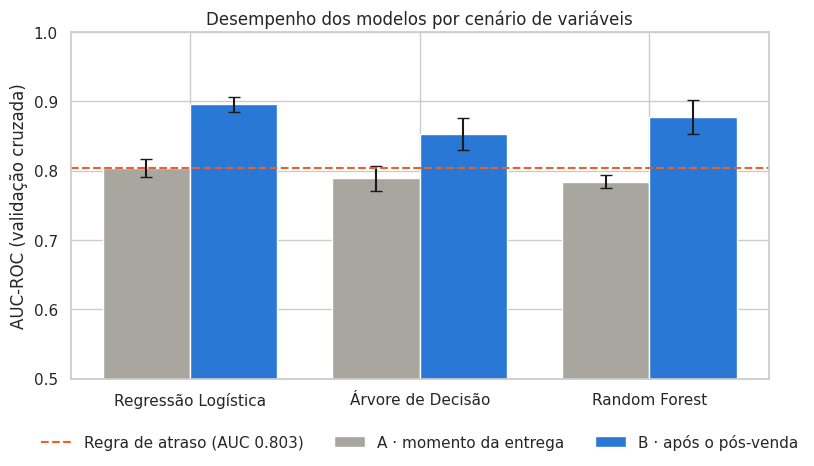

In [11]:
# ============================================================
# Célula 11 — Comparando a AUC média (± desvio) de cada combinação
# ============================================================
fig, ax = plt.subplots(figsize=(9, 4.5))
cores_cenario = {"A · momento da entrega": "#A8A69E", "B · após o pós-venda": "#2A78D6"}
largura = 0.38
posicoes = np.arange(len(modelos))
for i, (nome_cenario, cor) in enumerate(cores_cenario.items()):
    parte = tabela_cv[tabela_cv["cenario"] == nome_cenario]
    ax.bar(posicoes + (i - 0.5) * largura, parte["roc_auc_media"], largura,
           yerr=parte["roc_auc_desvio"], capsize=4, color=cor, label=nome_cenario)

# Linha de referência: AUC da regra de atraso calculada no treino (mesma base da validação)
auc_regra_treino = roc_auc_score(y_train, X_train["delivery_delay_days"])
ax.axhline(auc_regra_treino, color=cores_nps["Detrator"], linestyle="--",
           label=f"Regra de atraso (AUC {auc_regra_treino:.3f})")
ax.set_xticks(posicoes)
ax.set_xticklabels(modelos.keys())
ax.set_ylim(0.5, 1.0)
ax.set_ylabel("AUC-ROC (validação cruzada)")
ax.set_title("Desempenho dos modelos por cenário de variáveis")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=3, frameon=False)
plt.show()

### 📝 Análise dos resultados


- As barras **cinza** (cenário A) ficam praticamente **em cima da linha tracejada** da regra de atraso (AUC de 0,803 no treino). Com o que se sabe na entrega, **nenhum algoritmo faz melhor que a regra simples "atrasou, é risco"**: o atraso já carrega quase toda a informação disponível nesse momento.
- As barras **azuis** (cenário B) ficam claramente acima da regra em todos os modelos. **A informação do atendimento é o que dá valor ao modelo.**
- **Implicação prática:** na entrega, a empresa já pode agir com a regra simples (sem modelo); o modelo passa a fazer diferença quando os dados do SAC entram na conta.

# 8. ✅ Avaliação no conjunto de teste

Com o modelo escolhido na validação cruzada, treinamos com **todo o treino** e, pela primeira vez, abrimos o conjunto de **teste**. Avaliamos os dois cenários com a **Regressão Logística** (a justificativa da escolha está na análise da Seção 7) e mantemos a Random Forest do cenário B como comparação.

In [12]:
# ============================================================
# Célula 12 — Treinando os modelos finais e avaliando no teste
# ============================================================
def treinar_pipeline(variaveis_numericas, modelo):
    """Monta o pipeline (preparação + modelo) e treina com o conjunto de treino."""
    colunas = variaveis_numericas + variaveis_categoricas
    pipeline = Pipeline([
        ("preprocessamento", criar_preprocessador(variaveis_numericas)),
        ("modelo", modelo),
    ])
    pipeline.fit(X_train[colunas], y_train)
    return pipeline, colunas

modelo_a, colunas_a = treinar_pipeline(variaveis_cenario_a, LogisticRegression(max_iter=1000, random_state=SEED))
modelo_b, colunas_b = treinar_pipeline(variaveis_cenario_b, LogisticRegression(max_iter=1000, random_state=SEED))
modelo_rf, _ = treinar_pipeline(variaveis_cenario_b, RandomForestClassifier(
    n_estimators=300, min_samples_leaf=5, random_state=SEED, n_jobs=-1))

# predict_proba devolve a probabilidade de cada classe; a coluna [:, 1] é a de ser detrator
score_a = modelo_a.predict_proba(X_test[colunas_a])[:, 1]
score_b = modelo_b.predict_proba(X_test[colunas_b])[:, 1]
score_rf = modelo_rf.predict_proba(X_test[colunas_b])[:, 1]

# Com o ponto de corte padrão de 0,5: probabilidade >= 0,5 vira "detrator"
resultado_teste = pd.DataFrame({
    "Modelo bobo (sempre detrator)": avaliar_classificacao(y_test, previsao_bobo, np.zeros(len(y_test))),
    "Regra: atraso ≥ 1 dia":         avaliar_classificacao(y_test, previsao_regra, score_regra),
    "Logística · cenário A":         avaliar_classificacao(y_test, (score_a >= 0.5).astype(int), score_a),
    "Logística · cenário B":         avaliar_classificacao(y_test, (score_b >= 0.5).astype(int), score_b),
    "Random Forest · cenário B":     avaliar_classificacao(y_test, (score_rf >= 0.5).astype(int), score_rf),
}).T
resultado_teste

,acuracia,precision,recall,f1,auc_roc
Modelo bobo (sempre detrator),0.844,0.844,1.000,0.915,0.500
Regra: atraso ≥ 1 dia,0.834,0.881,0.929,0.904,0.784
Logística · cenário A,0.840,0.861,0.967,0.911,0.779
Logística · cenário B,0.858,0.886,0.955,0.919,0.868
Random Forest · cenário B,0.862,0.872,0.981,0.923,0.869


### 📝 Análise dos resultados


- **Logística · cenário B:** AUC de **0,868** no teste, contra **0,784** da regra de atraso. Precisão de **88,6%**, acima da taxa base de 84,4%. É o modelo escolhido.
- **Random Forest · cenário B:** AUC de 0,869, **empate técnico** com a Logística. Como não há ganho, ficamos com o modelo mais simples e explicável.
- **Logística · cenário A:** AUC de **0,779**, **abaixo** da regra de atraso (0,784). Confirma, agora em dados nunca vistos, o que a validação cruzada mostrou: sem o atendimento, o modelo não supera a regra.
- **Sem sinal de sobreajuste preocupante:** a AUC do cenário B caiu de 0,896 (validação cruzada) para 0,868 (teste), uma diferença compatível com a variação natural de uma amostra de 500 pedidos.
- Repare que a **acurácia** de todos os modelos fica entre 83% e 86%, colada aos 84,4% do modelo bobo. Se olhássemos só para ela, concluiríamos erradamente que nenhum modelo serve.

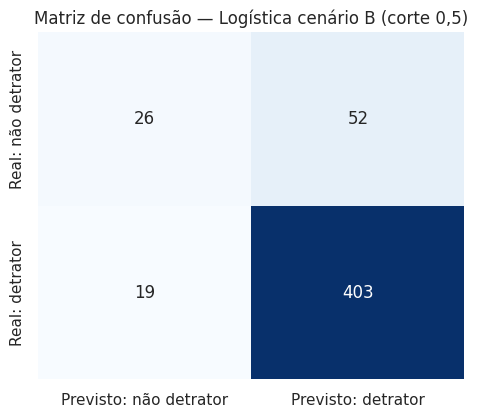

Verdadeiros positivos (detratores encontrados): 403
Falsos negativos (detratores que escaparam):    19
Falsos positivos (alarmes sem necessidade):     52
Verdadeiros negativos (satisfeitos poupados):   26

              precision    recall  f1-score   support

não detrator      0.578     0.333     0.423        78
    detrator      0.886     0.955     0.919       422

    accuracy                          0.858       500
   macro avg      0.732     0.644     0.671       500
weighted avg      0.838     0.858     0.842       500



In [13]:
# ============================================================
# Célula 13 — Matriz de confusão do modelo B (corte 0,5) e relatório por classe
# ============================================================
previsao_b = (score_b >= 0.5).astype(int)
matriz = confusion_matrix(y_test, previsao_b)

fig, ax = plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(matriz, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
            xticklabels=["Previsto: não detrator", "Previsto: detrator"],
            yticklabels=["Real: não detrator", "Real: detrator"])
ax.set_title("Matriz de confusão — Logística cenário B (corte 0,5)")
plt.show()

# Leitura da matriz: VN (canto sup. esq.), FP (sup. dir.), FN (inf. esq.), VP (inf. dir.)
vn, fp, fn, vp = matriz.ravel()
print(f"Verdadeiros positivos (detratores encontrados): {vp}")
print(f"Falsos negativos (detratores que escaparam):    {fn}")
print(f"Falsos positivos (alarmes sem necessidade):     {fp}")
print(f"Verdadeiros negativos (satisfeitos poupados):   {vn}")
print()
print(classification_report(y_test, previsao_b, target_names=["não detrator", "detrator"], digits=3))

### 📝 Análise dos resultados


- Dos **422 detratores** do teste, o modelo encontrou **403** e deixou escapar **19** (recall de 95,5%).
- Dos **78 não detratores**, o modelo reconheceu apenas **26** e gerou **52 alarmes sem necessidade** (recall da classe "não detrator" de apenas 33,3%).
- **Leitura:** com o corte de 0,5, o modelo marca **455 dos 500 pedidos** (91%) como risco. Para uma operação que não consegue atender todo mundo, isso pouco ajuda. O corte de 0,5 é só uma convenção e, com 84% de detratores, ele fica **baixo demais**. Na Seção 10 vamos escolher o corte pelo custo do erro e pela capacidade da equipe.

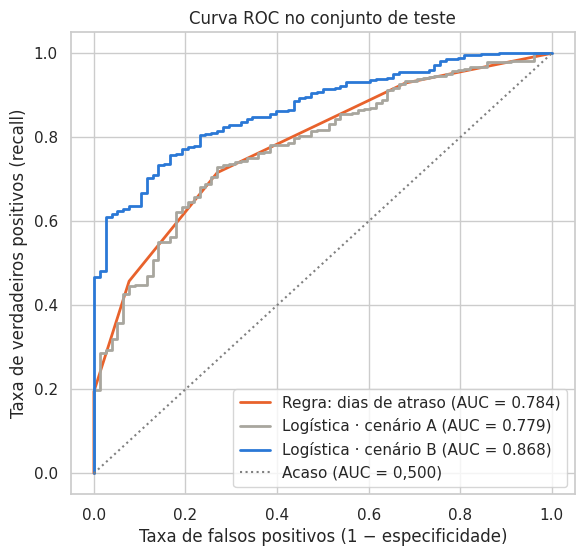

In [14]:
# ============================================================
# Célula 14 — Curvas ROC: regra de atraso × modelos A e B
# ============================================================
fig, ax = plt.subplots(figsize=(6.5, 6))
curvas = {
    "Regra: dias de atraso": (score_regra, cores_nps["Detrator"]),
    "Logística · cenário A": (score_a, "#A8A69E"),
    "Logística · cenário B": (score_b, "#2A78D6"),
}
for nome, (score, cor) in curvas.items():
    taxa_fp, taxa_vp, _ = roc_curve(y_test, score)
    ax.plot(taxa_fp, taxa_vp, color=cor, linewidth=2,
            label=f"{nome} (AUC = {roc_auc_score(y_test, score):.3f})")

# Diagonal = modelo que chuta ao acaso (AUC = 0,5)
ax.plot([0, 1], [0, 1], color="gray", linestyle=":", label="Acaso (AUC = 0,500)")
ax.set_xlabel("Taxa de falsos positivos (1 − especificidade)")
ax.set_ylabel("Taxa de verdadeiros positivos (recall)")
ax.set_title("Curva ROC no conjunto de teste")
ax.legend(loc="lower right")
plt.show()

### 📝 Análise dos resultados


- A curva **azul** (cenário B) fica acima das outras em praticamente toda a extensão: para qualquer nível de alarmes falsos que a empresa aceite, ela encontra mais detratores.
- As curvas da **regra de atraso** e do **cenário A** praticamente se sobrepõem (AUC de 0,784 e 0,779). Visualmente fica claro que o cenário A não acrescenta nada à regra.
- A "escada" da curva da regra aparece porque os dias de atraso são números inteiros (poucos valores distintos), o que limita a capacidade de ordenar os pedidos dentro de um mesmo dia de atraso.

# 9. 🔍 Interpretação do modelo: o que pesa no risco?

Um modelo que a área de negócio não entende dificilmente é adotado. Na regressão logística, cada coeficiente diz **para que lado** e **com que força** a variável move o risco. Como as variáveis foram padronizadas, os coeficientes são comparáveis: medem o efeito de **aumentar a variável em 1 desvio-padrão**. Transformamos em **razão de chances** (*odds ratio* = e<sup>coeficiente</sup>): acima de 1 aumenta o risco, abaixo de 1 reduz.

                        variavel  coeficiente  razao_de_chances
0            delivery_delay_days        1.549             4.707
1               complaints_count        1.185             3.269
2           resolution_time_days        0.692             1.998
3       customer_region_Nordeste        0.240             1.271
4      customer_service_contacts        0.163             1.176
5         customer_tenure_months        0.079             1.082
6          customer_region_Norte        0.077             1.080
7   customer_region_Centro-Oeste        0.060             1.061
8                  freight_value        0.056             1.058
9                 discount_value       -0.006             0.994
10          payment_installments       -0.006             0.994
11                  customer_age       -0.008             0.992
12            delivery_time_days       -0.082             0.922
13                items_quantity       -0.085             0.919
14             delivery_attempts       -

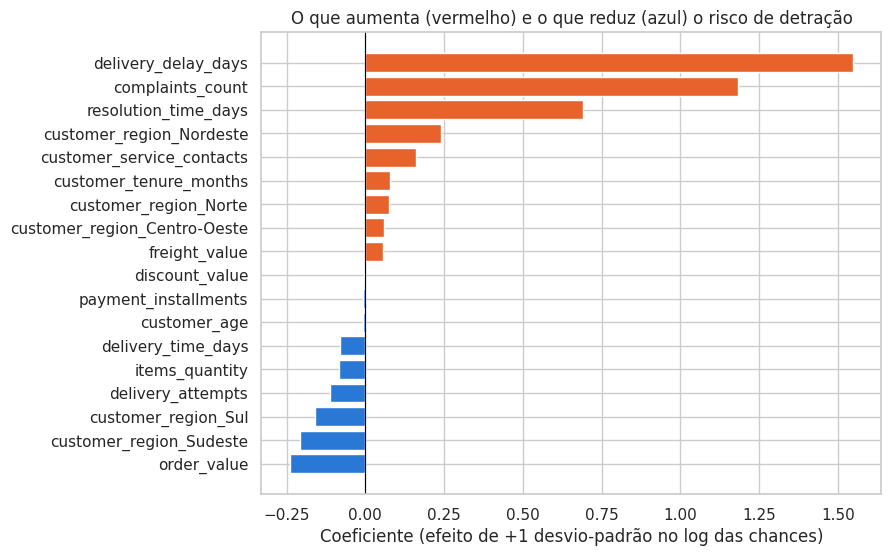

In [15]:
# ============================================================
# Célula 15 — Coeficientes e razão de chances da Logística (cenário B)
# ============================================================
nomes_variaveis = modelo_b.named_steps["preprocessamento"].get_feature_names_out()
coeficientes = modelo_b.named_steps["modelo"].coef_[0]

coef_df = pd.DataFrame({
    "variavel": [n.replace("num__", "").replace("cat__", "") for n in nomes_variaveis],
    "coeficiente": coeficientes,
    "razao_de_chances": np.exp(coeficientes),
}).sort_values("coeficiente", ascending=False).reset_index(drop=True)
print(coef_df)

# Gráfico de barras horizontais: vermelho aumenta o risco, azul reduz
fig, ax = plt.subplots(figsize=(8, 6))
cores = [cores_nps["Detrator"] if c > 0 else cores_nps["Promotor"] for c in coef_df["coeficiente"]]
ax.barh(coef_df["variavel"], coef_df["coeficiente"], color=cores)
ax.axvline(0, color="black", linewidth=0.8)
ax.invert_yaxis()
ax.set_xlabel("Coeficiente (efeito de +1 desvio-padrão no log das chances)")
ax.set_title("O que aumenta (vermelho) e o que reduz (azul) o risco de detração")
plt.show()

### 📝 Análise dos resultados


- **Os três fatores que mais aumentam o risco** (efeito de +1 desvio-padrão, mantendo o resto constante):
  - **Dias de atraso:** razão de chances de **4,7**. Cada ~1,5 dia a mais de atraso multiplica as chances de detração por quase cinco.
  - **Reclamações:** razão de chances de **3,3** (a cada ~1,8 reclamação a mais).
  - **Tempo de resolução:** razão de chances de **2,0** (a cada ~3,5 dias a mais para resolver).
- **Contatos com o SAC** têm efeito pequeno (1,18) quando as reclamações já estão no modelo: o que pesa não é o cliente ter falado com a empresa, é ele ter **reclamado** e esperado pela solução.
- **Perfil, preço e pagamento** (idade, tempo de casa, desconto, parcelas, frete) ficam com razão de chances próxima de **1**, sem efeito relevante. As regiões têm efeitos pequenos (Nordeste 1,27; Sudeste 0,81) e o valor do pedido aparece com leve efeito protetor (0,79), pontos que não apareceram com força na EDA e devem ser tratados com cautela.
- **O modelo confirma a história da EDA:** a insatisfação vem da **operação** (prazo e atendimento), não de quem é o cliente nem de quanto ele pagou.

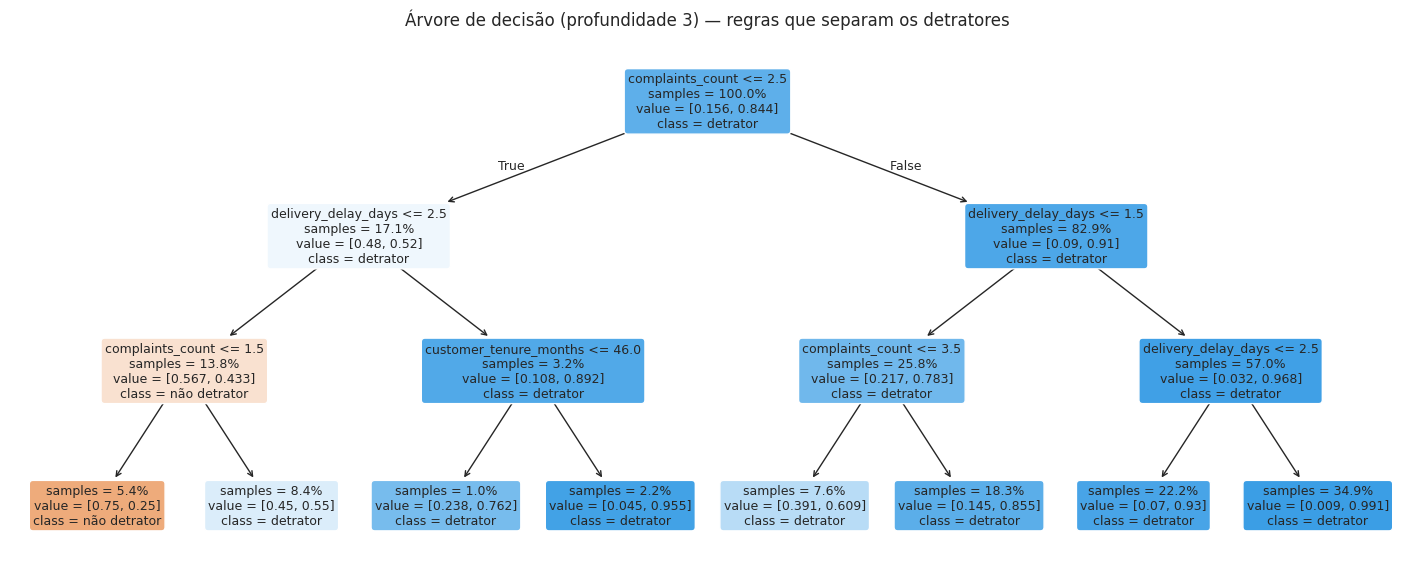

AUC da árvore rasa no teste: 0.836


In [16]:
# ============================================================
# Célula 16 — Árvore de decisão rasa: as regras em linguagem de negócio
# ============================================================
# Uma árvore com só 3 níveis, treinada SEM padronização, para ler os cortes nas unidades originais
arvore_explicativa = DecisionTreeClassifier(max_depth=3, min_samples_leaf=20, random_state=SEED)
arvore_explicativa.fit(X_train[variaveis_cenario_b], y_train)

fig, ax = plt.subplots(figsize=(18, 7))
plot_tree(arvore_explicativa, feature_names=variaveis_cenario_b,
          class_names=["não detrator", "detrator"], filled=True, rounded=True,
          proportion=True, impurity=False, fontsize=9, ax=ax)
ax.set_title("Árvore de decisão (profundidade 3) — regras que separam os detratores")
plt.show()

print("AUC da árvore rasa no teste:",
      round(roc_auc_score(y_test, arvore_explicativa.predict_proba(X_test[variaveis_cenario_b])[:, 1]), 3))

### 📝 Análise dos resultados


*(Na figura, azul = maioria detratora; laranja = maioria não detratora. `value` mostra a proporção [não detrator, detrator] em cada caixa.)*

- **Primeira pergunta da árvore: "o cliente fez 3 reclamações ou mais?"** Isso vale para **82,9%** dos pedidos, e 91% deles são detratores.
- **O caminho mais grave:** 3+ reclamações **e** 3+ dias de atraso reúne **34,9% dos pedidos**, com **99,1% de detratores**. Praticamente ninguém nesse grupo recomenda a empresa.
- **O único grupo "seguro":** até 1 reclamação **e** até 2 dias de atraso, apenas **5,4% dos pedidos**, com **75% de não detratores**.
- A árvore rasa tem AUC de **0,836**, abaixo da Logística (0,868), mas traduz o modelo em **regras que qualquer gestor entende**. Ela serve para comunicar o modelo e justificar a priorização, enquanto a Logística faz a pontuação.

# 10. 🎚️ Ponto de corte (threshold), custo do erro e lift

**Modelos de classificação entregam score, não vereditos.** O corte de 0,5 usado até aqui é só uma convenção. Quem decide o corte é o negócio, considerando:

- **Falso negativo** (detrator que escapou): o cliente fica insatisfeito, fala mal da marca e talvez não volte.
- **Falso positivo** (alarme sem necessidade): custo de um contato ou de um cupom para quem já estava satisfeito.
- **Capacidade operacional:** quantos pedidos o SAC consegue tratar por dia.

Corte **baixo** → mais pedidos acionados, mais recall, mais falsos positivos. Corte **alto** → menos custo, mais precisão, mais detratores escapando.

In [17]:
# ============================================================
# Célula 17 — Varrendo pontos de corte (Logística, cenário B)
# ============================================================
tabela_corte = []
for corte in [0.30, 0.50, 0.70, 0.80, 0.85, 0.90, 0.95]:
    previsto = (score_b >= corte).astype(int)
    vn, fp, fn, vp = confusion_matrix(y_test, previsto).ravel()
    tabela_corte.append({
        "corte": corte,
        "pedidos_acionados_%": previsto.mean() * 100,
        "precision": precision_score(y_test, previsto, zero_division=0),
        "recall": recall_score(y_test, previsto),
        "f1": f1_score(y_test, previsto),
        "VP": vp, "FP": fp, "FN": fn,
    })
tabela_corte = pd.DataFrame(tabela_corte)
tabela_corte

,corte,pedidos_acionados_%,precision,recall,f1,VP,FP,FN
0,0.300,96.400,0.869,0.993,0.927,419,63,3
1,0.500,91.000,0.886,0.955,0.919,403,52,19
2,0.700,84.800,0.908,0.912,0.910,385,39,37
3,0.800,78.200,0.923,0.855,0.888,361,30,61
4,0.850,73.200,0.940,0.815,0.873,344,22,78
5,0.900,64.200,0.966,0.735,0.834,310,11,112
6,0.950,49.000,0.992,0.576,0.729,243,2,179


### 📝 Análise dos resultados


- Subindo o corte de **0,5 para 0,9**, a equipe passa a acionar **64%** dos pedidos (em vez de 91%), a **precisão sobe de 88,6% para 96,6%** e os alarmes falsos caem de 52 para **11**. O preço é o recall: de 95,5% para **73,5%** (112 detratores ficam fora da lista).
- No corte de **0,95**, a lista cai para **49%** dos pedidos com precisão de **99,2%** (só 2 alarmes falsos), mas encontra apenas **57,6%** dos detratores.
- **Não existe corte "certo" do ponto de vista estatístico.** A escolha depende de quanto custa um alarme falso, quanto vale recuperar um detrator e quantos pedidos a equipe consegue atender por dia. É o que a próxima célula simula.

Ponto de equilíbrio: só compensa acionar se a precisão for > 83.3%
Acionar todos os pedidos:     R$ 160
Acionar só os atrasados:      R$ 635
Modelo B no melhor corte (0.90): R$ 1,275


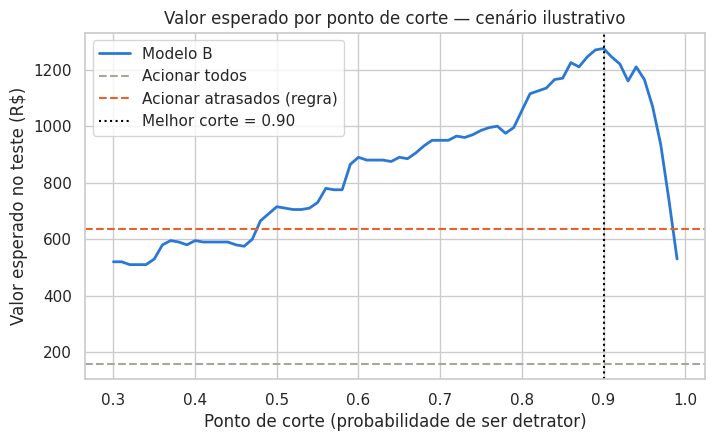

In [18]:
# ============================================================
# Célula 18 — Valor esperado de cada ponto de corte (cenário ILUSTRATIVO)
# ============================================================
# ATENÇÃO: valores hipotéticos, apenas para mostrar o raciocínio.
# A área de negócio deve substituir pelos números reais.
custo_por_acao = 25.0          # R$ por pedido acionado (contato do SAC + cupom de compensação)
valor_do_cliente = 150.0       # R$ que um cliente recuperado gera (recompra/indicação)
taxa_de_reversao = 0.20        # % dos detratores abordados que a ação consegue "virar"

# Ganho esperado = detratores abordados × chance de reverter × valor;  custo = todos os acionados × custo
cortes = np.round(np.arange(0.30, 1.00, 0.01), 2)
valor_esperado = []
for corte in cortes:
    previsto = score_b >= corte
    vp = (previsto & (y_test == 1)).sum()
    acionados = previsto.sum()
    valor_esperado.append(vp * taxa_de_reversao * valor_do_cliente - acionados * custo_por_acao)
valor_esperado = np.array(valor_esperado)

# Referência: acionar TODOS os pedidos (sem modelo)
valor_todos = y_test.sum() * taxa_de_reversao * valor_do_cliente - len(y_test) * custo_por_acao
# Referência: acionar só os atrasados (regra de negócio)
valor_regra = ((previsao_regra == 1) & (y_test == 1)).sum() * taxa_de_reversao * valor_do_cliente \
              - previsao_regra.sum() * custo_por_acao

melhor_corte = cortes[valor_esperado.argmax()]
print(f"Ponto de equilíbrio: só compensa acionar se a precisão for > {custo_por_acao / (taxa_de_reversao * valor_do_cliente):.1%}")
print(f"Acionar todos os pedidos:     R$ {valor_todos:,.0f}")
print(f"Acionar só os atrasados:      R$ {valor_regra:,.0f}")
print(f"Modelo B no melhor corte ({melhor_corte:.2f}): R$ {valor_esperado.max():,.0f}")

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(cortes, valor_esperado, color="#2A78D6", linewidth=2, label="Modelo B")
ax.axhline(valor_todos, color="#A8A69E", linestyle="--", label="Acionar todos")
ax.axhline(valor_regra, color=cores_nps["Detrator"], linestyle="--", label="Acionar atrasados (regra)")
ax.axvline(melhor_corte, color="black", linestyle=":", label=f"Melhor corte = {melhor_corte:.2f}")
ax.set_xlabel("Ponto de corte (probabilidade de ser detrator)")
ax.set_ylabel("Valor esperado no teste (R$)")
ax.set_title("Valor esperado por ponto de corte — cenário ilustrativo")
ax.legend()
plt.show()

### 📝 Análise dos resultados


> ⚠️ **Os valores em reais são hipotéticos** (custo da ação de R\$ 25, cliente recuperado vale R\$ 150, ação reverte 20% dos detratores). O objetivo é mostrar o **método**; os números reais devem vir da área de negócio.

- Com essas premissas, a ação só compensa quando a precisão passa de **83,3%**. Como 84,4% dos pedidos já são detratores, **acionar todo mundo** fica quase no zero a zero (**R\$ 160** nos 500 pedidos do teste).
- **Acionar só os atrasados** (regra) gera **R\$ 635**. **O modelo B no corte de 0,90** gera **R\$ 1.275**, cerca de **2 vezes** o valor da regra, porque concentra a ação onde a chance de ser detrator é muito alta e evita gastar com quem já está satisfeito.
- A curva é "serrilhada" porque o teste tem só 500 pedidos: pequenas mudanças de corte mudam poucos pedidos de lado. O ponto ótimo exato (0,90) não deve ser lido com precisão de casa decimal; o importante é que **a região de cortes altos (0,85 a 0,93) é a mais vantajosa** neste cenário.
- **Recomendação:** o corte de deploy deve ser escolhido junto com o negócio, com custos reais e o limite de capacidade do SAC, e revisado se esses números mudarem.

Taxa média de detratores no teste: 84.4%  →  lift máximo possível: 1.18
       pedidos  detratores  score_medio  taxa_detratores_%  lift  ganho_acumulado_%
decil                                                                              
1           50          50        0.999            100.000 1.185             11.848
2           50          50        0.994            100.000 1.185             23.697
3           50          50        0.986            100.000 1.185             35.545
4           50          49        0.973             98.000 1.161             47.156
5           50          49        0.959             98.000 1.161             58.768
6           50          43        0.932             86.000 1.019             68.957
7           50          41        0.895             82.000 0.972             78.673
8           50          34        0.831             68.000 0.806             86.730
9           50          33        0.675             66.000 0.782             94.550
10  

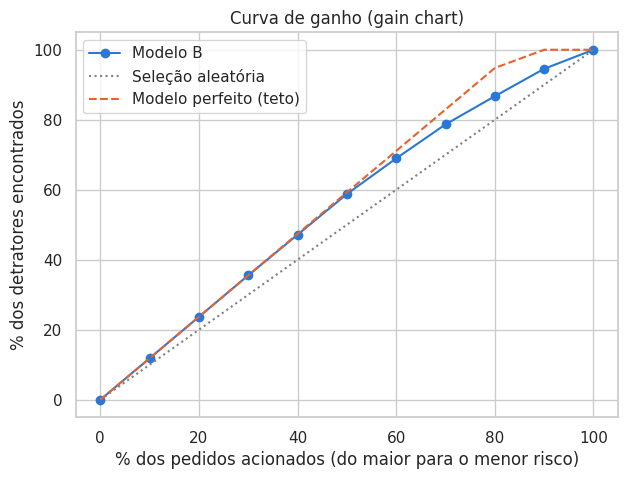

In [19]:
# ============================================================
# Célula 19 — Lift e curva de ganho por decil de risco
# ============================================================
# Ordenamos os pedidos do teste do maior para o menor score e dividimos em 10 faixas (decis)
ranking = pd.DataFrame({"score": score_b, "detrator": y_test.values})
ranking = ranking.sort_values("score", ascending=False).reset_index(drop=True)
ranking["decil"] = pd.qcut(ranking.index, 10, labels=range(1, 11))

taxa_media = ranking["detrator"].mean()
lift = ranking.groupby("decil", observed=True).agg(pedidos=("detrator", "size"),
                                                   detratores=("detrator", "sum"),
                                                   score_medio=("score", "mean"))
lift["taxa_detratores_%"] = lift["detratores"] / lift["pedidos"] * 100
lift["lift"] = (lift["detratores"] / lift["pedidos"]) / taxa_media
lift["ganho_acumulado_%"] = lift["detratores"].cumsum() / ranking["detrator"].sum() * 100
print(f"Taxa média de detratores no teste: {taxa_media:.1%}  →  lift máximo possível: {1 / taxa_media:.2f}")
print(lift)

# Curva de ganho: % dos detratores encontrados ao acionar os X% pedidos de maior risco
fig, ax = plt.subplots(figsize=(7, 5))
x = np.arange(0, 11) * 10
ax.plot(x, np.r_[0, lift["ganho_acumulado_%"].values], marker="o", color="#2A78D6", label="Modelo B")
ax.plot([0, 100], [0, 100], color="gray", linestyle=":", label="Seleção aleatória")
# Modelo perfeito: colocaria todos os detratores primeiro (teto da curva)
ax.plot(x, np.minimum(x / taxa_media, 100), color=cores_nps["Detrator"], linestyle="--", label="Modelo perfeito (teto)")
ax.set_xlabel("% dos pedidos acionados (do maior para o menor risco)")
ax.set_ylabel("% dos detratores encontrados")
ax.set_title("Curva de ganho (gain chart)")
ax.legend()
plt.show()

### 📝 Análise dos resultados


- **Lift máximo possível: 1,18.** Como 84,4% dos pedidos já são detratores, mesmo um modelo perfeito só pode chegar a 100% de detratores numa faixa, ou seja, 1,18 vez a taxa média. Um "lift de 3" é **matematicamente impossível** neste problema.
- Os **3 primeiros decis** (30% dos pedidos de maior risco) têm **100% de detratores** e atingem o lift máximo (1,185). Até o 5º decil, a taxa fica em 98%.
- **Onde o modelo mais ajuda é na outra ponta:** no **10º decil**, apenas **46%** são detratores (lift de 0,55). O modelo é muito bom em dizer **quem não precisa de ação**, o que evita gastar orçamento com clientes satisfeitos.
- Na curva de ganho, o modelo fica entre a seleção aleatória e o teto do modelo perfeito, praticamente colado no teto até 50% dos pedidos acionados (os 5 primeiros decis). A distância entre as curvas é pequena porque o próprio problema é generalizado: **com 84% de detratores, a solução de fundo é operacional (prazo e atendimento), e o modelo é uma ferramenta de priorização enquanto a causa não é corrigida.**

# 11. 📈 Complemento: prevendo a nota com regressão

Além de "vai ou não vai ser detrator", pode ser útil estimar **a nota esperada**. Repetimos o roteiro das aulas de regressão: separar treino e teste, comparar **Regressão Linear** com **Árvore de Decisão** e avaliar com **MAE, RMSE e R²**. Usamos as mesmas variáveis do cenário B e o mesmo sorteio de treino/teste.

In [20]:
# ============================================================
# Célula 20 — Regressão Linear × Árvore de Decisão para a nota de NPS
# ============================================================
# Mesma divisão de linhas da classificação: pegamos a nota pelos índices de X_train e X_test
y_train_nota = df.loc[X_train.index, "nps_score"]
y_test_nota = df.loc[X_test.index, "nps_score"]

regressores = {
    "Regressão Linear":  LinearRegression(),
    "Árvore de Decisão": DecisionTreeRegressor(max_depth=5, min_samples_leaf=20, random_state=SEED),
}
resultados_reg = []
previsoes_nota = {}
for nome, regressor in regressores.items():
    pipeline = Pipeline([("preprocessamento", criar_preprocessador(variaveis_cenario_b)),
                         ("modelo", regressor)])
    pipeline.fit(X_train[colunas_b], y_train_nota)
    previsto = pipeline.predict(X_test[colunas_b])
    previsoes_nota[nome] = previsto
    resultados_reg.append({
        "modelo": nome,
        "MAE": mean_absolute_error(y_test_nota, previsto),
        "RMSE": np.sqrt(mean_squared_error(y_test_nota, previsto)),
        "R2": r2_score(y_test_nota, previsto),
    })

# Linha de base: prever sempre a média do treino
media_treino = np.full(len(y_test_nota), y_train_nota.mean())
resultados_reg.append({"modelo": "Linha de base (média)",
                       "MAE": mean_absolute_error(y_test_nota, media_treino),
                       "RMSE": np.sqrt(mean_squared_error(y_test_nota, media_treino)),
                       "R2": r2_score(y_test_nota, media_treino)})
pd.DataFrame(resultados_reg)

,modelo,MAE,RMSE,R2
0,Regressão Linear,1.355,1.716,0.516
1,Árvore de Decisão,1.474,1.843,0.442
2,Linha de base (média),1.999,2.466,-0.000


### 📝 Análise dos resultados


| Modelo | MAE | RMSE | R² |
|---|---|---|---|
| Regressão Linear | **1,355** | **1,716** | **0,516** |
| Árvore de Decisão | 1,474 | 1,843 | 0,442 |
| Linha de base (média) | 1,999 | 2,466 | 0,000 |

- A **Regressão Linear** foi a melhor: erra a nota, em média, em **1,36 ponto** (contra 2,0 de quem chuta sempre a média) e explica **52%** da variação da nota. Como na classificação, o modelo mais simples ganhou: as relações entre atraso, reclamações e nota são aproximadamente **lineares**, como a regressão da EDA já sugeria.
- **Utilidade prática limitada:** um erro médio de 1,36 ponto é grande quando a fronteira entre detrator e neutro está em 7. Para decidir quem acionar, o **score de probabilidade da classificação** é mais adequado; a nota prevista serve como indicador complementar (por exemplo, para estimar o NPS esperado de um lote de pedidos).

   nota_real  nota_prevista   erro
0      7.400          5.283  2.117
1      1.400          2.848 -1.448
2      3.200          2.614  0.586
3      3.200          3.483 -0.283
4      5.900          5.720  0.180
5      7.200          4.693  2.507
6      2.400          2.331  0.069
7      5.600          2.530  3.070
8      4.900          3.405  1.495
9      4.200          5.402 -1.202


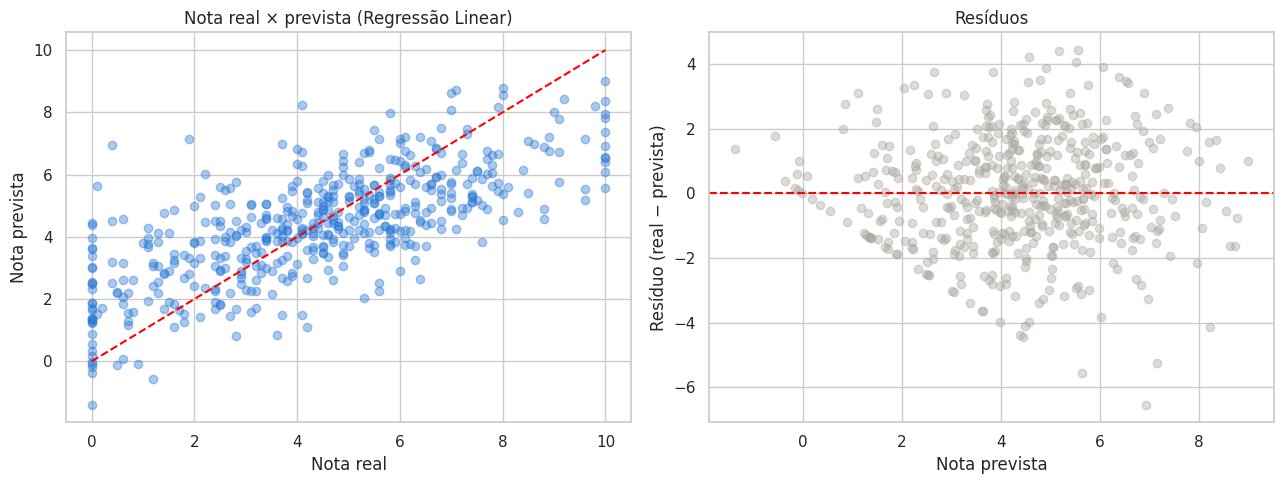

In [21]:
# ============================================================
# Célula 21 — Nota real × nota prevista (Regressão Linear)
# ============================================================
comparacao = pd.DataFrame({"nota_real": y_test_nota.values,
                           "nota_prevista": previsoes_nota["Regressão Linear"]})
comparacao["erro"] = comparacao["nota_real"] - comparacao["nota_prevista"]
print(comparacao.head(10))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
# Dispersão: quanto mais perto da diagonal, melhor a previsão
axes[0].scatter(comparacao["nota_real"], comparacao["nota_prevista"], alpha=0.4, color="#2A78D6")
axes[0].plot([0, 10], [0, 10], color="red", linestyle="--")
axes[0].set_xlabel("Nota real")
axes[0].set_ylabel("Nota prevista")
axes[0].set_title("Nota real × prevista (Regressão Linear)")
# Resíduos: devem se espalhar ao redor de zero, sem padrão
axes[1].scatter(comparacao["nota_prevista"], comparacao["erro"], alpha=0.4, color="#A8A69E")
axes[1].axhline(0, color="red", linestyle="--")
axes[1].set_xlabel("Nota prevista")
axes[1].set_ylabel("Resíduo (real − prevista)")
axes[1].set_title("Resíduos")
plt.tight_layout()
plt.show()

### 📝 Análise dos resultados


- Os pontos acompanham a diagonal, mas com bastante dispersão, coerente com o R² de 0,52.
- Dois comportamentos merecem atenção:
  - **Notas reais iguais a 0:** há uma coluna de pontos no zero com previsões entre −1 e 4,5. A nota tem limite em 0, e a regressão linear não sabe disso (chega a prever **valores negativos**, que não existem na escala).
  - **Notas altas (8 a 10) são subestimadas:** a maioria dos pontos à direita fica abaixo da diagonal. Com poucos promotores na base, o modelo "puxa" as previsões para a média.
- Os resíduos se espalham ao redor de zero, sem um funil evidente, mas os limites da escala (0 e 10) indicam que um modelo de **classificação** é a forma mais natural de tratar esse problema.

# 12. 🚀 Uso na prática: salvando o modelo e pontuando novos pedidos

Na fase de **Implantação (Deploy)** do CRISP-DM o modelo sai do notebook e vira parte da rotina. O desenho proposto:

1. **Retreinar** o pipeline final com **todos** os dados disponíveis (treino + teste), já que a avaliação terminou.
2. **Salvar** o pipeline completo (preparação + modelo) em um arquivo `.joblib`, na pasta `models/` do repositório.
3. Todos os dias, um processo **carrega o arquivo**, pontua os pedidos entregues e envia ao SAC/CRM uma **lista priorizada por faixa de risco**.
4. **Monitorar**: comparar o risco previsto com as notas que chegam, acompanhar a distribuição das variáveis (*data drift*) e retreinar periodicamente.

In [22]:
# ============================================================
# Célula 22 — Retreinando com toda a base e salvando o pipeline
# ============================================================
modelo_final = Pipeline([
    ("preprocessamento", criar_preprocessador(variaveis_cenario_b)),
    ("modelo", LogisticRegression(max_iter=1000, random_state=SEED)),
])
modelo_final.fit(X[colunas_b], y)   # todas as 2.500 linhas

# No repositório, salva na pasta models/ da raiz; no Colab, cria models/ na sessão
pasta_modelos = "../models" if os.path.isdir("../models") else "models"
os.makedirs(pasta_modelos, exist_ok=True)
caminho_modelo = os.path.join(pasta_modelos, "modelo_detrator_logistica.joblib")
joblib.dump(modelo_final, caminho_modelo)
print("Modelo salvo em:", caminho_modelo, f"({os.path.getsize(caminho_modelo) / 1024:.1f} KB)")

Modelo salvo em: ../models/modelo_detrator_logistica.joblib (5.1 KB)


### 📝 Análise dos resultados


- O pipeline final (preparação + Regressão Logística do cenário B) foi retreinado com os **2.500 pedidos** e salvo em `models/modelo_detrator_logistica.joblib`, com apenas **5,1 KB**.
- Por salvar o **pipeline inteiro**, quem for usar o modelo não precisa repetir a padronização nem a criação das dummies: basta enviar os dados brutos do pedido.
- No repositório do projeto, esse arquivo vai para a pasta `models/`.

In [23]:
# ============================================================
# Célula 23 — Função de uso: pontuar pedidos novos e sugerir a ação
# ============================================================
# Faixas de risco: os limites devem vir da análise de custo/capacidade (Seção 10)
LIMITE_RISCO_ALTO = 0.90
LIMITE_RISCO_MEDIO = 0.70

def pontuar_pedidos(novos_pedidos, caminho=caminho_modelo):
    """Carrega o modelo salvo, calcula o risco de detração e sugere a ação para cada pedido."""
    modelo = joblib.load(caminho)
    resultado = novos_pedidos[["order_id"]].copy()
    resultado["risco_detrator"] = modelo.predict_proba(novos_pedidos[colunas_b])[:, 1]
    resultado["faixa_risco"] = pd.cut(resultado["risco_detrator"],
                                      bins=[0, LIMITE_RISCO_MEDIO, LIMITE_RISCO_ALTO, 1.0001],
                                      right=False, labels=["Baixo", "Médio", "Alto"])
    acoes = {"Alto": "Contato ativo do SAC + compensação",
             "Médio": "Aviso proativo por mensagem",
             "Baixo": "Fluxo padrão"}
    resultado["acao_sugerida"] = resultado["faixa_risco"].map(acoes)
    return resultado.sort_values("risco_detrator", ascending=False)

# Simulação: 8 pedidos "novos" (aqui, linhas sorteadas da base, sem a coluna de nota)
pedidos_do_dia = df.drop(columns=["nps_score", "categoria_nps", "detrator"]).sample(8, random_state=SEED)
pontuar_pedidos(pedidos_do_dia)

,order_id,risco_detrator,faixa_risco,acao_sugerida
1583,51584,1.000,Alto,Contato ativo do SAC + compensação
668,50669,0.996,Alto,Contato ativo do SAC + compensação
2287,52288,0.960,Alto,Contato ativo do SAC + compensação
1447,51448,0.870,Médio,Aviso proativo por mensagem
2404,52405,0.765,Médio,Aviso proativo por mensagem
1114,51115,0.563,Baixo,Fluxo padrão
1537,51538,0.366,Baixo,Fluxo padrão
1064,51065,0.149,Baixo,Fluxo padrão


### 📝 Análise dos resultados


- A função devolve, para cada pedido, o **risco de detração** (de 0 a 1), a **faixa de risco** e a **ação sugerida**, já ordenados do maior para o menor risco. É essa tabela que o SAC/CRM receberia todos os dias.
- No exemplo, 3 dos 8 pedidos caíram na faixa **Alto** (risco ≥ 0,90), 2 na faixa **Médio** e 3 na faixa **Baixo**.
- Os limites das faixas (0,70 e 0,90) seguem a análise da Seção 10, mas são **parâmetros de negócio**: devem ser ajustados à capacidade da equipe e aos custos reais.
- **Uso indevido a evitar:** o score serve para **melhorar a experiência** de quem está em risco, nunca para escolher quem recebe a pesquisa de NPS. Excluir clientes insatisfeitos da pesquisa "melhoraria" o indicador sem melhorar nada na operação.

In [24]:
# ============================================================
# Célula 24 — As faixas de risco funcionam? (checagem no conjunto de teste)
# ============================================================
# Usamos o modelo B treinado só com o treino, para a checagem ser honesta
checagem = pd.DataFrame({"risco": score_b, "detrator": y_test.values})
checagem["faixa_risco"] = pd.cut(checagem["risco"], bins=[0, LIMITE_RISCO_MEDIO, LIMITE_RISCO_ALTO, 1.0001],
                                 right=False, labels=["Baixo", "Médio", "Alto"])
resumo_faixas = checagem.groupby("faixa_risco", observed=True).agg(
    pedidos=("detrator", "size"),
    risco_medio_previsto=("risco", "mean"),
    taxa_real_detratores=("detrator", "mean"),
)
resumo_faixas["%_dos_pedidos"] = resumo_faixas["pedidos"] / len(checagem) * 100
resumo_faixas

,pedidos,risco_medio_previsto,taxa_real_detratores,%_dos_pedidos
faixa_risco,,,,
Baixo,76,0.422,0.487,15.200
Médio,103,0.827,0.728,20.600
Alto,321,0.970,0.966,64.200


### 📝 Análise dos resultados


| Faixa | % dos pedidos | Risco médio previsto | Detratores reais |
|---|---|---|---|
| Alto | 64,2% | 97,0% | **96,6%** |
| Médio | 20,6% | 82,7% | **72,8%** |
| Baixo | 15,2% | 42,2% | **48,7%** |

- As faixas **separam bem** os pedidos: a taxa real de detratores cai de 96,6% (Alto) para 72,8% (Médio) e 48,7% (Baixo).
- O risco previsto está **próximo da realidade** nas faixas Alto e Baixo; na faixa Médio, o modelo superestima um pouco (82,7% previsto contra 72,8% real). Antes do deploy, vale **calibrar** as probabilidades e acompanhar essa diferença no monitoramento.
- **Ponto de atenção operacional:** a faixa Alto concentra **64% dos pedidos**. Se o SAC não tiver capacidade para tudo isso, a lista deve ser cortada pelo topo do ranking (top-K), começando pelos maiores scores.

# 13. 🧾 Conclusões, limitações e próximos passos

### 📌 Respostas aos itens pedidos no desafio

| Item | Decisão |
|---|---|
| **Variável-alvo** | `detrator` = 1 se a nota for de 0 a 6 (metodologia oficial do NPS). Classe positiva com 84,4% da base. |
| **Variáveis de entrada** | Perfil, pedido, entrega e atendimento (13 numéricas + região). **Excluídas por vazamento:** recompra em 30 dias (calculada a partir da nota) e CSAT interno (outra medida de satisfação). |
| **Separação dos dados** | 80% treino / 20% teste, estratificada, `random_state=42`. Escolha do modelo por validação cruzada estratificada de 5 partes, somente no treino. |
| **Modelo** | Regressão Logística com pipeline de preparação: maior AUC na validação cruzada, mais estável, leve e interpretável. |
| **Avaliação** | AUC-ROC (principal), precisão acima da taxa base, matriz de confusão, varredura de pontos de corte, valor esperado e lift/curva de ganho. Acurácia descartada como critério. |
| **Uso na prática** | Pipeline salvo em `models/`; pontuação diária dos pedidos; lista priorizada por faixa de risco para o SAC/CRM; monitoramento e retreino periódico. |

### 📝 Registro das descobertas

| Observação | Evidência | Hipótese associada | Próximos passos |
|---|---|---|---|
| Com o que se sabe na entrega, nenhum modelo supera a regra "atrasou, é risco" | AUC 0,779 (modelo A) × 0,784 (regra) no teste | O atraso concentra quase toda a informação disponível nesse momento | Usar a regra simples já, sem esperar o modelo |
| Os dados de atendimento elevam a AUC de ~0,80 para ~0,87–0,90 | Validação cruzada e teste | Reclamar e esperar pela solução agrava a insatisfação causada pelo atraso | Confirmar se reclamações são registradas **antes** da pesquisa |
| Logística e Random Forest empatam | AUC 0,868 × 0,869 no teste | O problema tem relações aproximadamente lineares | Manter o modelo mais simples |
| Lift limitado a 1,18 | 84,4% de detratores na base | A insatisfação é sistêmica, não de um nicho | Tratar a causa (prazo) em paralelo ao modelo |
| Corte alto gera mais valor que acionar todos | Cenário ilustrativo: corte 0,90 ≈ 2× a regra | Evitar ações em clientes satisfeitos economiza orçamento | Recalcular com custos reais e capacidade do SAC |

### 📖 A história em uma frase (E / MAS / PORTANTO)
- **E:** 84% dos clientes são detratores, e o atraso e as reclamações explicam a maior parte das notas baixas;
- **MAS:** a empresa só descobre a insatisfação quando a pesquisa chega, e não consegue tratar todos os pedidos;
- **PORTANTO:** usamos a regra de atraso na entrega e, quando os dados de atendimento chegam, um modelo que ordena os pedidos por risco (AUC 0,87) para concentrar a ação proativa onde ela tem mais chance de evitar um detrator.

### ⚠️ Limitações
- **Dados com sinais de simulação** (notas decimais, recompra determinística, distribuições regulares demais): em dados reais, o desempenho tende a ser **menor** que o observado aqui.
- **Momento das variáveis de atendimento não confirmado.** Se reclamações e contatos forem registrados depois da pesquisa, o cenário B tem vazamento e só o cenário A (equivalente à regra de atraso) é válido.
- **Sem datas:** não foi possível fazer validação temporal nem avaliar sazonalidade.
- **Teste com 500 pedidos e só 78 não detratores:** as métricas da classe minoritária têm incerteza grande.
- **Valores financeiros hipotéticos** na análise de ponto de corte.
- **Associação não é causa:** o modelo indica **quem** está em risco, não prova **que** a ação proativa reduz a detração. Isso exige o **teste A/B** desenhado na EDA.

### 🔜 Próximos passos
1. Validar com o SAC o momento de registro das reclamações e dos contatos.
2. Obter as datas dos pedidos para refazer a separação de forma temporal e acompanhar sazonalidade.
3. Definir com o negócio os custos reais e a capacidade diária, e recalcular o ponto de corte.
4. Calibrar as probabilidades do modelo antes do deploy.
5. Rodar o **teste A/B** do aviso proativo usando o score para escolher os pedidos elegíveis.
6. Em produção, monitorar AUC, taxa de detratores por faixa de risco e *data drift* das variáveis, com retreino periódico.